In [32]:
from pathlib import Path
from zipfile import ZipFile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle, FancyArrowPatch
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss
from sklearn.calibration import calibration_curve

plt.rcParams.update({
    'figure.figsize': (11, 5.5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.22,
    'font.size': 10,
})
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

# ---- Data access: KaggleHub, local CSV, then supplied archive ----
PROJECT_DIR = Path.cwd()
def has_local_dataset(folder):
    return (
        (folder / 'archive (1).zip').is_file()
        or any(
            '2009' in path.name and '2018' in path.name
            for path in folder.glob('*.csv')
        )
    )

if not has_local_dataset(PROJECT_DIR) and has_local_dataset(PROJECT_DIR.parent):
    PROJECT_DIR = PROJECT_DIR.parent
ZIP_PATH = PROJECT_DIR / 'archive (1).zip'
PREFER_KAGGLE = True
KAGGLE_HANDLE = 'maxhorowitz/nflplaybyplay2009to2016'
CSV_PATH = None
DATA_SOURCE = None
REQUIRED_COLUMNS = {
    'game_id', 'game_date', 'home_team', 'away_team', 'posteam_type',
    'qtr', 'quarter_seconds_remaining', 'game_seconds_remaining',
    'down', 'ydstogo', 'yardline_100',
    'play_type', 'yards_gained', 'home_wp_post', 'epa', 'desc', 'drive',
    'total_home_score', 'total_away_score', 'home_timeouts_remaining',
    'away_timeouts_remaining', 'fourth_down_converted',
    'fourth_down_failed', 'touchdown', 'interception', 'fumble_lost',
}

if PREFER_KAGGLE:
    try:
        import kagglehub

        downloaded = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        kaggle_csvs = [
            p for p in downloaded.rglob('*.csv')
            if '2009' in p.name and '2018' in p.name
        ]
        if not kaggle_csvs:
            raise FileNotFoundError(
                f'Kaggle download at {downloaded} did not contain a 2009–2018 CSV.'
            )
        CSV_PATH = kaggle_csvs[0]
        DATA_SOURCE = f'KaggleHub: {KAGGLE_HANDLE} ({CSV_PATH.name})'
    except Exception as exc:
        warnings.warn(
            f'Kaggle access failed ({type(exc).__name__}: {exc}). '
            'Trying a local 2009–2018 CSV, then the supplied archive.',
            RuntimeWarning,
        )

if CSV_PATH is None:
    local_csvs = sorted(
        path for path in PROJECT_DIR.glob('*.csv')
        if '2009' in path.name and '2018' in path.name
    )
    if local_csvs:
        CSV_PATH = local_csvs[0]
        DATA_SOURCE = f'Local CSV: {CSV_PATH.name}'

if CSV_PATH is not None:
    df = pd.read_csv(
        CSV_PATH,
        usecols=lambda name: name in REQUIRED_COLUMNS,
        na_values=['NA'],
        low_memory=False,
    )
elif ZIP_PATH.is_file():
    with ZipFile(ZIP_PATH) as archive:
        members = [
            name for name in archive.namelist()
            if name.lower().endswith('.csv')
            and '2009' in Path(name).name
            and '2018' in Path(name).name
        ]
        if not members:
            raise FileNotFoundError(
                'The supplied ZIP has no CSV whose filename covers 2009–2018.'
            )
        member = members[-1]
        with archive.open(member) as source:
            df = pd.read_csv(
                source,
                usecols=lambda name: name in REQUIRED_COLUMNS,
                na_values=['NA'],
                low_memory=False,
            )
        DATA_SOURCE = f'{ZIP_PATH.name} -> {member}'
else:
    raise FileNotFoundError(
        'No usable dataset was found. Allow KaggleHub access, or place a '
        '2009–2018 CSV or archive (1).zip beside the notebook. Dataset: '
        'https://www.kaggle.com/datasets/maxhorowitz/nflplaybyplay2009to2016'
    )

missing = REQUIRED_COLUMNS.difference(df.columns)
if missing:
    raise ValueError(f'Dataset is missing required columns: {sorted(missing)}')
df['game_date'] = pd.to_datetime(df['game_date'], errors='coerce')
df['game_year'] = df['game_date'].dt.year
df['game_id'] = df['game_id'].astype(str)
print(f'Data source: {DATA_SOURCE}')
print(f'Rows: {len(df):,} | seasons: {df.game_year.min()}–{df.game_year.max()}')
print(f'Games: {df.game_id.nunique():,} | columns loaded: {len(df.columns)}')

# ---- Game outcomes, time snapshots, and leakage-safe predictor ----
for column in [
    'qtr', 'quarter_seconds_remaining', 'game_seconds_remaining',
    'down', 'ydstogo', 'yardline_100',
    'yards_gained', 'home_wp_post', 'epa', 'total_home_score',
    'total_away_score', 'home_timeouts_remaining', 'away_timeouts_remaining',
    'fourth_down_converted', 'fourth_down_failed', 'drive',
    'touchdown', 'interception', 'fumble_lost',
]:
    df[column] = pd.to_numeric(df[column], errors='coerce')

score_rows = df.dropna(
    subset=[
        'qtr', 'game_seconds_remaining',
        'total_home_score', 'total_away_score',
    ]
)
ordered = score_rows.sort_values(
    ['game_id', 'qtr', 'game_seconds_remaining'],
    ascending=[True, True, False],
)
final_rows = ordered.groupby('game_id', sort=False).tail(1).copy()
outcomes = final_rows[['game_id', 'total_home_score', 'total_away_score']].copy()
outcomes['home_win'] = np.where(
    outcomes['total_home_score'] > outcomes['total_away_score'],
    1.0,
    np.where(
        outcomes['total_home_score'] < outcomes['total_away_score'],
        0.0,
        np.nan,
    ),
)
df = df.merge(outcomes[['game_id', 'home_win']], on='game_id', how='left')

snapshot_rows = df.dropna(
    subset=[
        'game_year', 'game_seconds_remaining', 'qtr',
        'total_home_score', 'total_away_score', 'home_win',
    ]
).copy()
snapshot_rows['time_bin'] = (
    snapshot_rows['game_seconds_remaining'].clip(lower=0) // 300
).astype(int)
snapshot_rows = (
    snapshot_rows.sort_values(
        ['game_id', 'game_seconds_remaining'],
        ascending=[True, True],
    )
    .drop_duplicates(['game_id', 'time_bin'], keep='first')
    .copy()
)
snapshot_rows['home_score_diff'] = (
    snapshot_rows['total_home_score'] - snapshot_rows['total_away_score']
)
snapshot_rows['home_offense'] = np.where(
    snapshot_rows['posteam_type'].eq('home'),
    1.0,
    np.where(snapshot_rows['posteam_type'].eq('away'), 0.0, np.nan),
)
BASE_FEATURES = [
    'home_score_diff', 'game_seconds_remaining', 'qtr', 'down', 'ydstogo',
    'yardline_100', 'home_offense', 'home_timeouts_remaining',
    'away_timeouts_remaining',
]
for feature in BASE_FEATURES:
    snapshot_rows[feature] = pd.to_numeric(
        snapshot_rows[feature], errors='coerce'
    )
snapshot_rows['abs_score_diff'] = snapshot_rows['home_score_diff'].abs()
snapshot_rows['score_sum'] = (
    snapshot_rows['total_home_score'] + snapshot_rows['total_away_score']
)
snapshot_rows['timeout_diff'] = (
    snapshot_rows['home_timeouts_remaining']
    - snapshot_rows['away_timeouts_remaining']
)
snapshot_rows['score_per_minute'] = snapshot_rows['home_score_diff'] / (
    1 + snapshot_rows['game_seconds_remaining'] / 60
)
snapshot_rows['down_distance'] = snapshot_rows['down'] * snapshot_rows['ydstogo']
snapshot_rows['late_close'] = (
    (snapshot_rows['game_seconds_remaining'] <= 600)
    & (snapshot_rows['home_score_diff'].abs() <= 8)
).astype(float)
snapshot_rows['red_zone'] = (
    snapshot_rows['yardline_100'] <= 20
).astype(float)
snapshot_rows['territory'] = pd.cut(
    snapshot_rows['yardline_100'],
    bins=[-1, 20, 50, 80, 100],
    labels=False,
).astype(float)
ENGINEERED_FEATURES = [
    'abs_score_diff', 'score_sum', 'timeout_diff', 'score_per_minute',
    'down_distance', 'late_close', 'red_zone', 'territory',
]
FEATURES = [*BASE_FEATURES, *ENGINEERED_FEATURES]

train = snapshot_rows[snapshot_rows['game_year'].between(2009, 2016)].copy()
test = snapshot_rows[snapshot_rows['game_year'].between(2017, 2018)].copy()
if train.empty or test.empty:
    raise ValueError(
        f'Chronological split is empty: train={len(train)}, test={len(test)}. '
        'Confirm the source contains seasons 2009–2018.'
    )
if train['home_win'].nunique() < 2:
    raise ValueError('Training data must include both home wins and home losses.')

selection_train = train[train['game_year'].between(2009, 2014)]
selection_validation = train[train['game_year'].between(2015, 2016)]
if selection_train.empty or selection_validation.empty:
    raise ValueError('Model selection requires seasons 2009–2016.')

baseline_parameters = {
    'loss': 'log_loss', 'learning_rate': 0.08, 'max_iter': 140,
    'max_leaf_nodes': 15, 'min_samples_leaf': 35,
    'l2_regularization': 2.0, 'random_state': 42,
}
engineered_parameters = {
    'loss': 'log_loss', 'learning_rate': 0.06, 'max_iter': 220,
    'max_leaf_nodes': 15, 'min_samples_leaf': 60,
    'l2_regularization': 3.0, 'random_state': 42,
}
baseline_candidate = HistGradientBoostingClassifier(**baseline_parameters)
engineered_candidate = HistGradientBoostingClassifier(**engineered_parameters)
baseline_candidate.fit(
    selection_train[BASE_FEATURES], selection_train['home_win']
)
engineered_candidate.fit(
    selection_train[FEATURES], selection_train['home_win']
)
baseline_validation_loss = log_loss(
    selection_validation['home_win'],
    baseline_candidate.predict_proba(selection_validation[BASE_FEATURES])[:, 1],
    labels=[0, 1],
)
engineered_validation_loss = log_loss(
    selection_validation['home_win'],
    engineered_candidate.predict_proba(selection_validation[FEATURES])[:, 1],
    labels=[0, 1],
)
use_engineered_features = (
    engineered_validation_loss < baseline_validation_loss
)
model_features = FEATURES if use_engineered_features else BASE_FEATURES
model_parameters = (
    engineered_parameters if use_engineered_features else baseline_parameters
)
print(f'2015–2016 model-selection log loss, original features: {baseline_validation_loss:.4f}')
print(f'2015–2016 model-selection log loss, engineered features: {engineered_validation_loss:.4f}')
print(f'Model selected using validation seasons: {"engineered" if use_engineered_features else "original"} features')

baseline_model = HistGradientBoostingClassifier(**baseline_parameters)
baseline_model.fit(train[BASE_FEATURES], train['home_win'])
test['baseline_probability'] = baseline_model.predict_proba(
    test[BASE_FEATURES]
)[:, 1].clip(1e-6, 1 - 1e-6)

win_model = HistGradientBoostingClassifier(**model_parameters)
win_model.fit(train[model_features], train['home_win'])
test['predicted_home_win'] = win_model.predict_proba(
    test[model_features]
)[:, 1]
test['model_probability'] = test['predicted_home_win'].clip(1e-6, 1 - 1e-6)
test['reference_probability'] = test['home_wp_post'].clip(1e-6, 1 - 1e-6)
test_eval = test.dropna(
    subset=['home_win', 'model_probability', 'reference_probability']
).copy()
if test_eval.empty:
    raise ValueError('No complete held-out rows are available for log-loss evaluation.')

model_logloss = log_loss(
    test_eval['home_win'],
    test_eval['model_probability'],
    labels=[0, 1],
)
baseline_logloss = log_loss(
    test_eval['home_win'],
    test_eval['baseline_probability'],
    labels=[0, 1],
)
reference_logloss = log_loss(
    test_eval['home_win'],
    test_eval['reference_probability'],
    labels=[0, 1],
)
print(
    f'Train: {train.game_year.min()}–{train.game_year.max()} '
    f'({train.game_id.nunique():,} games, {len(train):,} snapshots)'
)
print(
    f'Test: {test_eval.game_year.min()}–{test_eval.game_year.max()} '
    f'({test_eval.game_id.nunique():,} games, {len(test_eval):,} snapshots)'
)
tie_count = int(
    outcomes['total_home_score'].eq(outcomes['total_away_score']).sum()
)
missing_outcome_games = df['game_id'].nunique() - outcomes['game_id'].nunique()
print(f'Tied games excluded from binary win/loss modeling: {tie_count}')
print(f'Games without a complete final score excluded: {missing_outcome_games}')
print(f'Original-feature baseline log loss: {baseline_logloss:.4f}')
print(f'Engineered-feature model log loss: {model_logloss:.4f}')
print(f'Source home_wp_post reference log loss: {reference_logloss:.4f}')

# Select the most volatile test game by the sum of observed play-to-play
# home-probability changes; this is a reproducible descriptive selection rule.
CASE_GAME_ID = None  # Optional: set to a game_id string from the held-out seasons.
test_game_ids = set(test_eval['game_id'])
holdout_plays = df[df['game_id'].isin(test_game_ids)].copy()
holdout_plays = holdout_plays.sort_values(
    ['game_id', 'qtr', 'game_seconds_remaining'],
    ascending=[True, True, False],
)
holdout_plays['observed_home_swing'] = (
    holdout_plays.groupby('game_id')['home_wp_post'].diff().abs()
)
volatility = holdout_plays.groupby('game_id')['observed_home_swing'].sum()
if CASE_GAME_ID is None:
    CASE_GAME_ID = str(volatility.idxmax())
else:
    CASE_GAME_ID = str(CASE_GAME_ID)
if CASE_GAME_ID not in test_game_ids:
    raise ValueError(
        f'CASE_GAME_ID {CASE_GAME_ID} is not in the 2017–2018 held-out seasons.'
    )

case_snapshot = test_eval[test_eval['game_id'].eq(CASE_GAME_ID)].copy()
case_plays = df[df['game_id'].eq(CASE_GAME_ID)].copy()
case_plays = case_plays.sort_values(
    ['qtr', 'game_seconds_remaining'],
    ascending=[True, False],
)
home_team = case_plays['home_team'].dropna().iloc[0]
away_team = case_plays['away_team'].dropna().iloc[0]
final_score = outcomes[outcomes['game_id'].eq(CASE_GAME_ID)].iloc[0]
home_won = bool(final_score['home_win'])
print(
    f'Case-study game: {CASE_GAME_ID} | {away_team} at {home_team} | '
    f'final {int(final_score.total_away_score)}–{int(final_score.total_home_score)} '
    f'(home {"win" if home_won else "loss"})'
)


C:\Users\henri\AppData\Local\Temp\ipykernel_67856\3284623929.py:70: RuntimeWarning:

Kaggle access failed (ModuleNotFoundError: No module named 'kagglehub'). Trying a local 2009–2018 CSV, then the supplied archive.



Data source: archive (1).zip -> NFL Play by Play 2009-2018 (v5).csv
Rows: 449,371 | seasons: 2009–2018
Games: 2,526 | columns loaded: 27
2015–2016 model-selection log loss, original features: 0.4842
2015–2016 model-selection log loss, engineered features: 0.4836
Model selected using validation seasons: engineered features
Train: 2009–2016 (2,019 games, 26,244 snapshots)
Test: 2017–2018 (493 games, 4,539 snapshots)
Tied games excluded from binary win/loss modeling: 14
Games without a complete final score excluded: 0
Original-feature baseline log loss: 0.4354
Engineered-feature model log loss: 0.4339
Source home_wp_post reference log loss: 0.4359
Case-study game: 2018100703 | BAL at CLE | final 9–12 (home win)


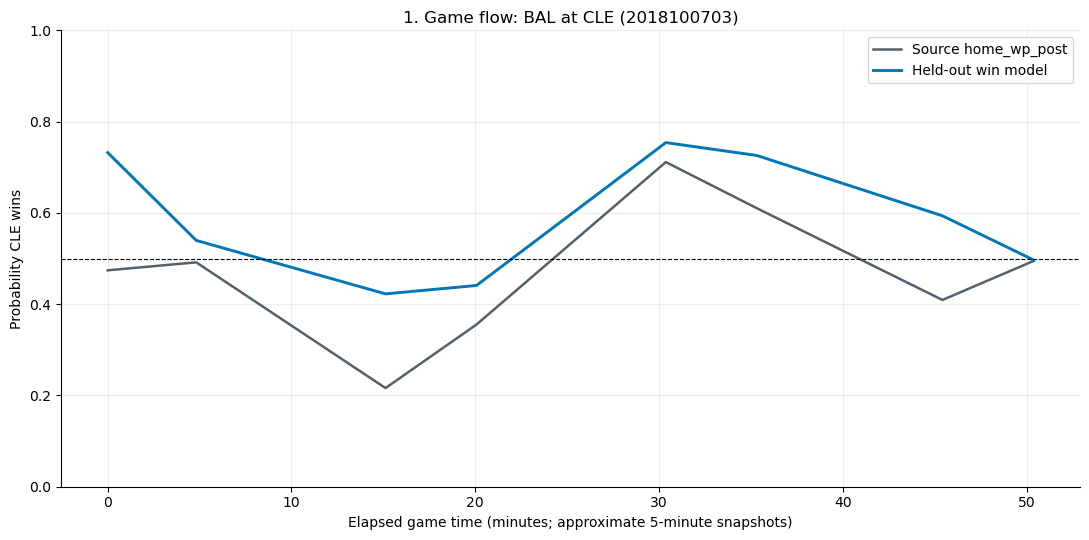

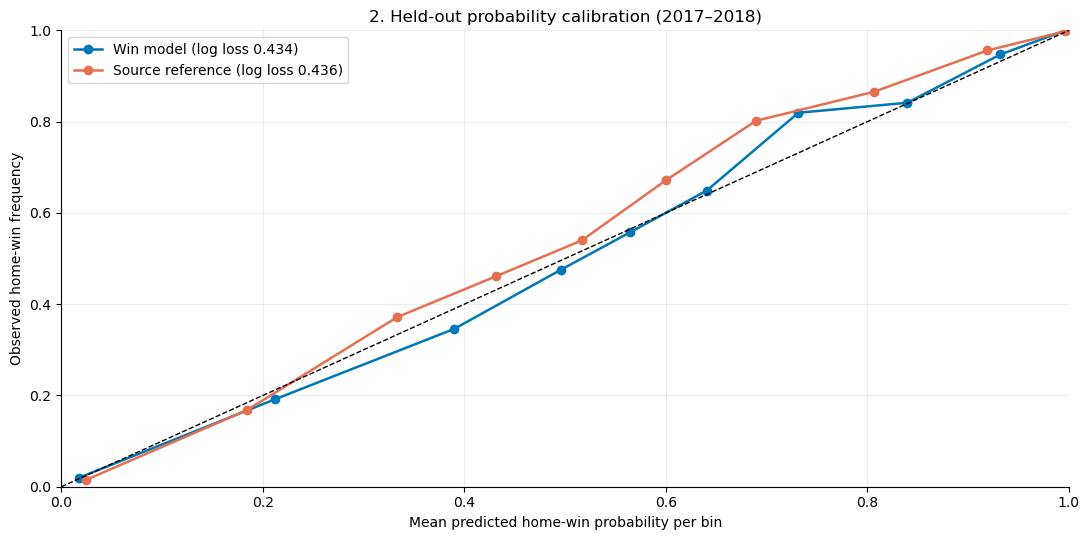

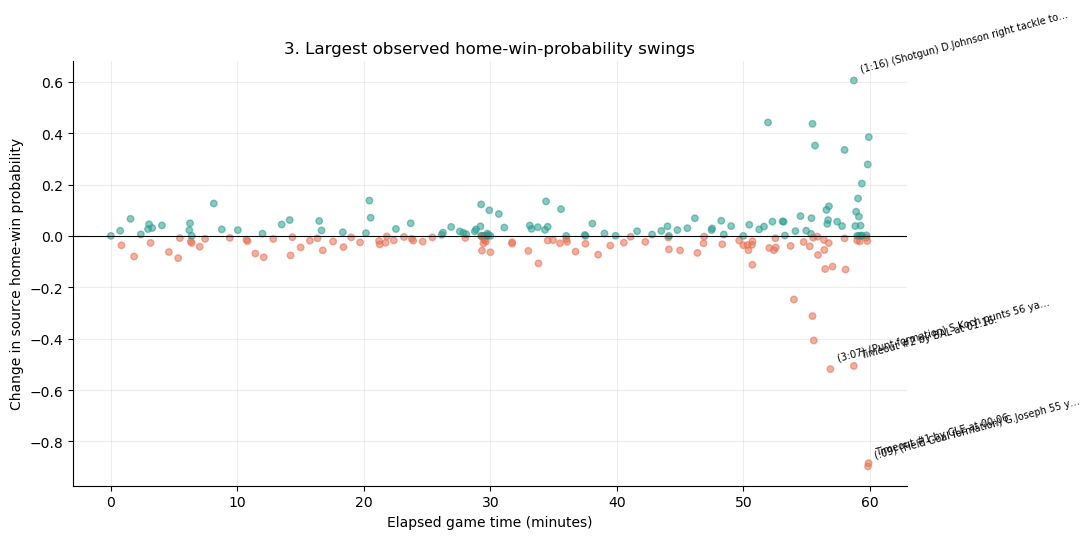

Largest observed swing plays:


,qtr,game_seconds_remaining,play_type,home_wp_change,home_wp_post,desc
420052,5,187.0,punt,-0.518,0.253,(3:07) (Punt formation) S.Koch punts 56 yards ...
420058,5,76.0,run,0.605,0.605,(1:16) (Shotgun) D.Johnson right tackle to BAL...
420057,5,76.0,no_play,-0.506,0.000,Timeout #2 by BAL at 01:16.
420025,4,9.0,field_goal,-0.897,0.025,(:09) (Field Goal formation) G.Joseph 55 yard ...
420061,5,6.0,no_play,-0.884,0.000,Timeout #1 by CLE at 00:06.


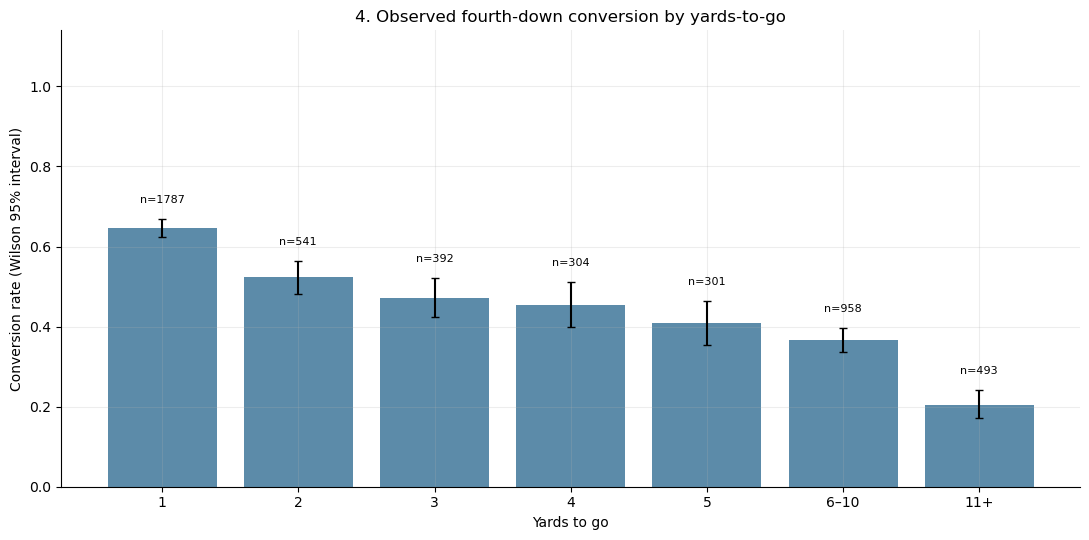

Fourth-down attempts with explicit outcomes: 4,776


,distance_group,successes,attempts,rate,low,high,error_low,error_high
0,1,1157,1787,0.647,0.625,0.669,0.022,0.022
1,2,283,541,0.523,0.481,0.565,0.042,0.042
2,3,185,392,0.472,0.423,0.521,0.049,0.049
3,4,138,304,0.454,0.399,0.510,0.055,0.056
4,5,123,301,0.409,0.355,0.465,0.054,0.056
5,6–10,351,958,0.366,0.336,0.397,0.030,0.031
6,11+,101,493,0.205,0.172,0.243,0.033,0.038


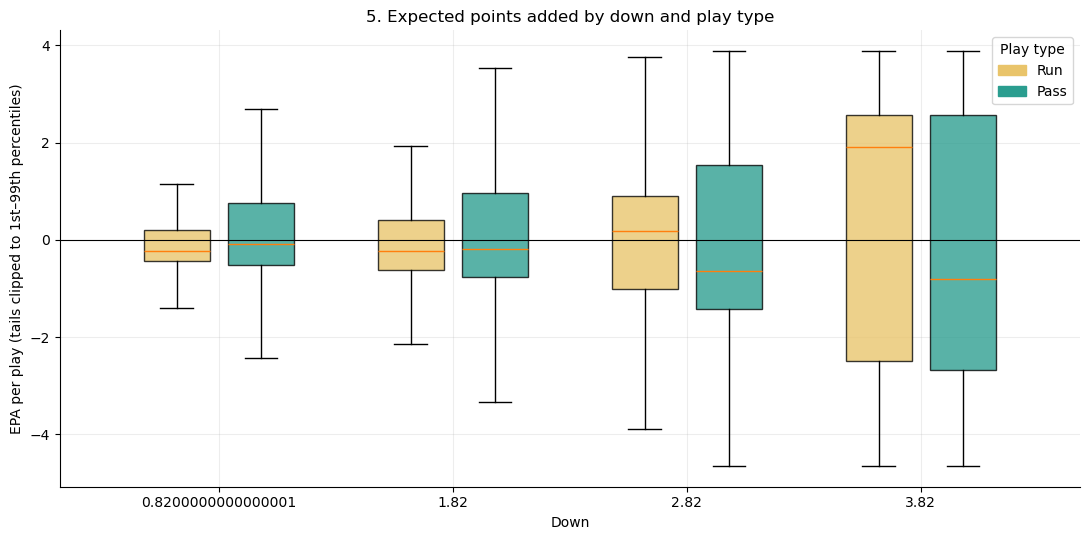

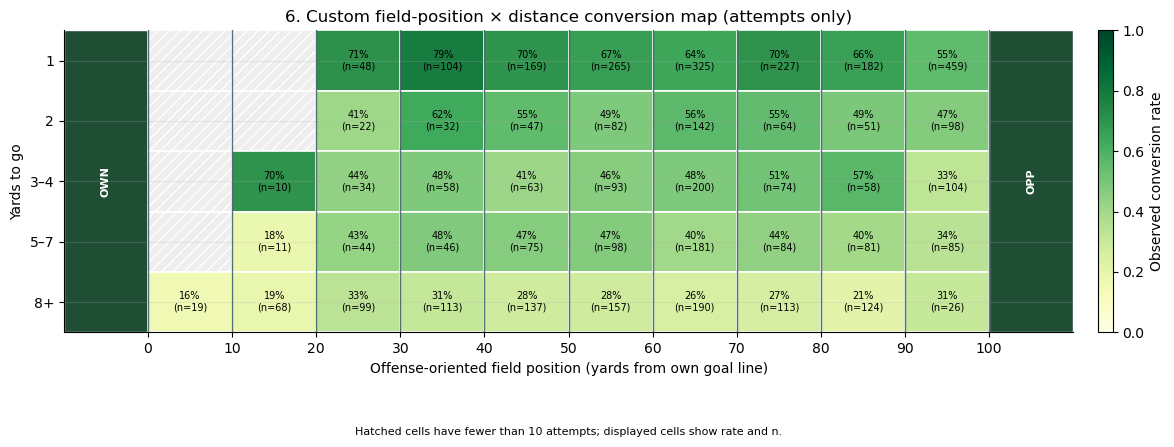

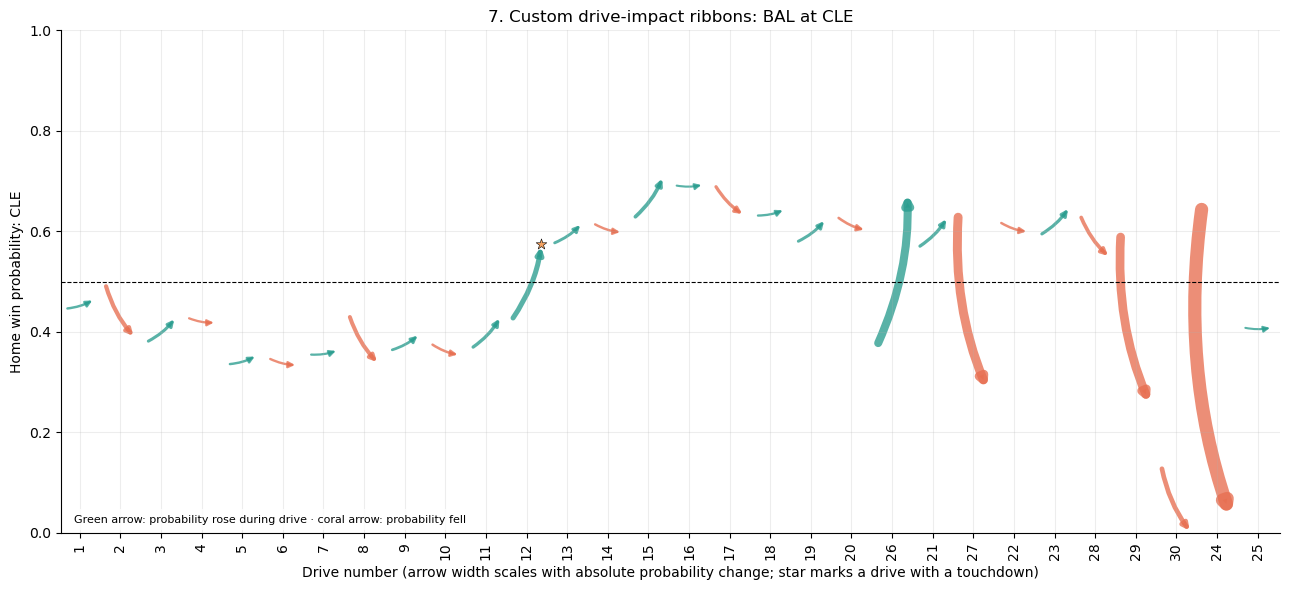

Case Study 2 evidence: 4,776 fourth-down attempts with explicit outcomes; overall observed conversion rate 49.0%.
Interpretation reminder: these are selected attempts, not the causal value of choosing to go for it.


In [33]:
# ---- Figure 1 (core): selected game's game-flow win-probability timeline ----
game_plot = case_snapshot.sort_values(
    'game_seconds_remaining', ascending=False
).copy()
game_plot['elapsed_minutes'] = (
    game_plot['game_seconds_remaining'].max()
    - game_plot['game_seconds_remaining']
) / 60
fig, ax = plt.subplots()
ax.plot(
    game_plot['elapsed_minutes'],
    game_plot['reference_probability'],
    color='#52616b',
    linewidth=1.8,
    label='Source home_wp_post',
)
ax.plot(
    game_plot['elapsed_minutes'],
    game_plot['model_probability'],
    color='#0077b6',
    linewidth=2.1,
    label='Held-out win model',
)
ax.axhline(0.5, color='black', linewidth=0.8, linestyle='--')
ax.set(
    title=f'1. Game flow: {away_team} at {home_team} ({CASE_GAME_ID})',
    xlabel='Elapsed game time (minutes; approximate 5-minute snapshots)',
    ylabel=f'Probability {home_team} wins',
    ylim=(0, 1),
)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

# ---- Figure 2 (core): held-out calibration, annotated with requested log loss ----
fig, ax = plt.subplots()
for label, probability, color in [
    ('Win model', test_eval['model_probability'], '#0077b6'),
    ('Source reference', test_eval['reference_probability'], '#e76f51'),
]:
    observed, predicted = calibration_curve(
        test_eval['home_win'],
        probability,
        n_bins=10,
        strategy='quantile',
    )
    score = (
        model_logloss if label == 'Win model' else reference_logloss
    )
    ax.plot(
        predicted,
        observed,
        marker='o',
        linewidth=1.8,
        color=color,
        label=f'{label} (log loss {score:.3f})',
    )
ax.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1)
ax.set(
    title='2. Held-out probability calibration (2017–2018)',
    xlabel='Mean predicted home-win probability per bin',
    ylabel='Observed home-win frequency',
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

# ---- Figure 3 (core): selected-game high-leverage plays ----
leverage = case_plays.dropna(subset=['home_wp_post']).copy()
leverage['home_wp_change'] = leverage['home_wp_post'].diff().fillna(0)
leverage['elapsed_minutes'] = (
    leverage['game_seconds_remaining'].max()
    - leverage['game_seconds_remaining']
) / 60
largest = leverage.loc[
    leverage['home_wp_change'].abs().nlargest(5).index
].sort_values('elapsed_minutes')
fig, ax = plt.subplots()
colors = np.where(leverage['home_wp_change'] >= 0, '#2a9d8f', '#e76f51')
ax.scatter(
    leverage['elapsed_minutes'],
    leverage['home_wp_change'],
    c=colors,
    alpha=0.55,
    s=22,
    label='Play-to-play change',
)
ax.axhline(0, color='black', linewidth=0.8)
for _, row in largest.iterrows():
    description = str(row.get('desc', 'play')).replace('\n', ' ')
    short_description = description[:42] + ('…' if len(description) > 42 else '')
    ax.annotate(
        short_description,
        (row['elapsed_minutes'], row['home_wp_change']),
        xytext=(4, 6),
        textcoords='offset points',
        fontsize=7,
        rotation=15,
    )
ax.set(
    title='3. Largest observed home-win-probability swings',
    xlabel='Elapsed game time (minutes)',
    ylabel='Change in source home-win probability',
)
plt.tight_layout()
plt.show()
print('Largest observed swing plays:')
display(
    largest[
        [
            'qtr', 'game_seconds_remaining', 'play_type', 'home_wp_change',
            'home_wp_post', 'desc',
        ]
    ].assign(
        home_wp_change=lambda x: x.home_wp_change.round(3),
        home_wp_post=lambda x: x.home_wp_post.round(3),
    )
)

# ---- Fourth-down data for Case Study 2 ----
fourth = df[df['down'].eq(4)].copy()
fourth['converted'] = fourth['fourth_down_converted'].eq(1)
fourth['failed'] = fourth['fourth_down_failed'].eq(1)
fourth = fourth[fourth['converted'] | fourth['failed']].copy()
fourth['success'] = fourth['converted'].astype(int)
fourth = fourth.dropna(subset=['ydstogo', 'yardline_100'])
if fourth.empty:
    raise ValueError(
        'No explicit fourth_down_converted/fourth_down_failed attempts were found.'
    )
fourth['distance_group'] = pd.cut(
    fourth['ydstogo'],
    bins=[0, 1, 2, 3, 4, 5, 10, 100],
    labels=['1', '2', '3', '4', '5', '6–10', '11+'],
    include_lowest=False,
)

def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return np.nan, np.nan
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half = z * np.sqrt(
        p * (1 - p) / total + z**2 / (4 * total**2)
    ) / denominator
    return max(0.0, center - half), min(1.0, center + half)

# ---- Figure 4 (core): fourth-down conversion by yards-to-go ----
distance_summary = (
    fourth.dropna(subset=['distance_group'])
    .groupby('distance_group', observed=False)['success']
    .agg(successes='sum', attempts='count', rate='mean')
    .reset_index()
)
distance_summary = distance_summary[distance_summary['attempts'] > 0].copy()
intervals = [
    wilson_interval(row.successes, row.attempts)
    for row in distance_summary.itertuples()
]
distance_summary['low'] = [value[0] for value in intervals]
distance_summary['high'] = [value[1] for value in intervals]
distance_summary['error_low'] = distance_summary['rate'] - distance_summary['low']
distance_summary['error_high'] = distance_summary['high'] - distance_summary['rate']
fig, ax = plt.subplots()
x = np.arange(len(distance_summary))
ax.bar(x, distance_summary['rate'], color='#457b9d', alpha=0.88)
ax.errorbar(
    x,
    distance_summary['rate'],
    yerr=[
        distance_summary['error_low'],
        distance_summary['error_high'],
    ],
    fmt='none',
    ecolor='black',
    capsize=3,
)
for index, row in distance_summary.iterrows():
    ax.text(
        index,
        min(1.03, row['high'] + 0.035),
        f"n={int(row['attempts'])}",
        ha='center',
        va='bottom',
        fontsize=8,
    )
ax.set_xticks(x, distance_summary['distance_group'].astype(str))
ax.set(
    title='4. Observed fourth-down conversion by yards-to-go',
    xlabel='Yards to go',
    ylabel='Conversion rate (Wilson 95% interval)',
    ylim=(0, 1.14),
)
plt.tight_layout()
plt.show()
print(f'Fourth-down attempts with explicit outcomes: {len(fourth):,}')
display(distance_summary.round(3))

# ---- Figure 5 (core): EPA distributions by down and run/pass play type ----
epa_data = df[
    df['down'].isin([1, 2, 3, 4])
    & df['play_type'].isin(['run', 'pass'])
].dropna(subset=['epa']).copy()
epa_data['epa'] = epa_data['epa'].clip(
    epa_data['epa'].quantile(0.01),
    epa_data['epa'].quantile(0.99),
)
fig, ax = plt.subplots()
positions = {
    ('run', down): down - 0.18
    for down in [1, 2, 3, 4]
}
positions.update({
    ('pass', down): down + 0.18
    for down in [1, 2, 3, 4]
})
box_data, box_positions, box_colors = [], [], []
for play_type, color in [('run', '#e9c46a'), ('pass', '#2a9d8f')]:
    for down in [1, 2, 3, 4]:
        values = epa_data.loc[
            epa_data['play_type'].eq(play_type) & epa_data['down'].eq(down),
            'epa',
        ]
        if not values.empty:
            box_data.append(values.to_numpy())
            box_positions.append(positions[(play_type, down)])
            box_colors.append(color)
boxes = ax.boxplot(
    box_data,
    positions=box_positions,
    widths=0.28,
    patch_artist=True,
    showfliers=False,
)
for patch, color in zip(boxes['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.78)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks([1, 2, 3, 4])
ax.set(
    title='5. Expected points added by down and play type',
    xlabel='Down',
    ylabel='EPA per play (tails clipped to 1st–99th percentiles)',
)
ax.legend(
    handles=[
        mpl.patches.Patch(color='#e9c46a', label='Run'),
        mpl.patches.Patch(color='#2a9d8f', label='Pass'),
    ],
    title='Play type',
)
plt.tight_layout()
plt.show()

# ---- Figure 6 (custom): hand-coded 100-yard field-position outcome map ----
# Coordinates convert yardline_100 (yards from opponent goal) to offense-
# oriented yards from own goal. Rectangles encode observed success rates.
field = fourth.copy()
field['yards_from_own_goal'] = 100 - field['yardline_100']
field['field_zone'] = pd.cut(
    field['yards_from_own_goal'],
    bins=np.arange(0, 110, 10),
    labels=np.arange(0, 100, 10),
    include_lowest=True,
    right=False,
)
field['distance_band'] = pd.cut(
    field['ydstogo'],
    bins=[0, 1, 2, 4, 7, 100],
    labels=['1', '2', '3–4', '5–7', '8+'],
    include_lowest=False,
)
field_summary = (
    field.dropna(subset=['field_zone', 'distance_band'])
    .groupby(['distance_band', 'field_zone'], observed=False)['success']
    .agg(rate='mean', attempts='count')
    .reset_index()
)
field_pivot = field_summary.pivot(
    index='distance_band', columns='field_zone', values='rate'
)
count_pivot = field_summary.pivot(
    index='distance_band', columns='field_zone', values='attempts'
)
distance_labels = ['1', '2', '3–4', '5–7', '8+']
field_edges = np.arange(0, 101, 10)
cmap = plt.get_cmap('YlGn')
norm = mpl.colors.Normalize(vmin=0, vmax=1)
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.set_facecolor('#dcebd7')
ax.add_patch(Rectangle((-10, 0), 10, len(distance_labels), facecolor='#204e35', edgecolor='white', zorder=0))
ax.add_patch(Rectangle((100, 0), 10, len(distance_labels), facecolor='#204e35', edgecolor='white', zorder=0))
for row_index, distance in enumerate(distance_labels):
    for col_index, left in enumerate(field_edges[:-1]):
        rate = field_pivot.reindex(
            index=distance_labels,
            columns=field_edges[:-1],
        ).iloc[row_index, col_index]
        attempts = count_pivot.reindex(
            index=distance_labels,
            columns=field_edges[:-1],
        ).iloc[row_index, col_index]
        is_sparse = pd.isna(attempts) or attempts < 10
        patch = Rectangle(
            (left, row_index),
            10,
            1,
            facecolor='#eeeeee' if is_sparse else cmap(norm(rate)),
            edgecolor='white',
            linewidth=1.2,
            hatch='///' if is_sparse else None,
        )
        ax.add_patch(patch)
        if not is_sparse:
            ax.text(
                left + 5,
                row_index + 0.5,
                f'{rate:.0%}\n(n={int(attempts)})',
                ha='center',
                va='center',
                fontsize=7,
                color='black',
            )
for yard in range(0, 101, 10):
    ax.axvline(yard, color='#264653', linewidth=1.0, alpha=0.75)
ax.set_xlim(-10, 110)
ax.set_ylim(0, len(distance_labels))
ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(len(distance_labels)) + 0.5, distance_labels)
ax.invert_yaxis()
ax.set(
    title='6. Custom field-position × distance conversion map (attempts only)',
    xlabel='Offense-oriented field position (yards from own goal line)',
    ylabel='Yards to go',
)
ax.text(-5, len(distance_labels) / 2, 'OWN', color='white', ha='center', va='center', rotation=90, fontsize=8, fontweight='bold')
ax.text(105, len(distance_labels) / 2, 'OPP', color='white', ha='center', va='center', rotation=90, fontsize=8, fontweight='bold')
colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    pad=0.02,
)
colorbar.set_label('Observed conversion rate')
ax.text(
    0.5,
    -0.34,
    'Hatched cells have fewer than 10 attempts; displayed cells show rate and n.',
    transform=ax.transAxes,
    ha='center',
    fontsize=8,
)
plt.tight_layout()
plt.show()

# ---- Figure 7 (custom): drive-impact ribbons for the case-study game ----
drive_rows = case_plays.dropna(subset=['drive', 'home_wp_post']).copy()
drive_summary = (
    drive_rows.sort_values('game_seconds_remaining', ascending=False)
    .groupby('drive', sort=False)
    .agg(
        start_wp=('home_wp_post', 'first'),
        end_wp=('home_wp_post', 'last'),
        offense=('posteam_type', 'first'),
        first_time=('game_seconds_remaining', 'first'),
        touchdown=('touchdown', 'max'),
    )
    .reset_index()
)
if drive_summary.empty:
    warnings.warn('No drive identifiers with win-probability values; figure 7 skipped.')
else:
    fig, ax = plt.subplots(figsize=(13, 6))
    for index, row in drive_summary.iterrows():
        start = float(row['start_wp'])
        end = float(row['end_wp'])
        color = '#2a9d8f' if end >= start else '#e76f51'
        width = 1.5 + min(abs(end - start) * 14, 8)
        arrow = FancyArrowPatch(
            (index + 0.08, start),
            (index + 0.82, end),
            arrowstyle='-|>',
            mutation_scale=9,
            connectionstyle='arc3,rad=0.12',
            linewidth=width,
            color=color,
            alpha=0.78,
        )
        ax.add_patch(arrow)
        if bool(row['touchdown']):
            ax.scatter(
                index + 0.8,
                end,
                marker='*',
                s=65,
                color='#f4a261',
                edgecolor='black',
                linewidth=0.4,
                zorder=4,
            )
    ax.axhline(0.5, color='black', linestyle='--', linewidth=0.8)
    ax.set_xlim(0, len(drive_summary))
    ax.set_ylim(0, 1)
    ax.set_xticks(
        np.arange(len(drive_summary)) + 0.45,
        [str(int(value)) for value in drive_summary['drive']],
        rotation=90,
    )
    ax.set(
        title=f'7. Custom drive-impact ribbons: {away_team} at {home_team}',
        xlabel='Drive number (arrow width scales with absolute probability change; star marks a drive with a touchdown)',
        ylabel=f'Home win probability: {home_team}',
    )
    ax.text(
        0.01,
        0.02,
        'Green arrow: probability rose during drive · coral arrow: probability fell',
        transform=ax.transAxes,
        fontsize=8,
        bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
    )
    plt.tight_layout()
    plt.show()

# ---- Case-study 2 summary / interpretation evidence ----
print(
    f'Case Study 2 evidence: {len(fourth):,} fourth-down attempts with '
    f'explicit outcomes; overall observed conversion rate '
    f'{fourth.success.mean():.1%}.'
)
print(
    'Interpretation reminder: these are selected attempts, not the causal '
    'value of choosing to go for it.'
)


In [34]:
"""Interactive Plotly and ipywidgets hub for the NFL analysis notebook."""

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import clear_output, display
from plotly.subplots import make_subplots
from sklearn.calibration import calibration_curve


def show_visualization_hub(
    *,
    df: pd.DataFrame,
    test_eval: pd.DataFrame,
    case_game_id: str,
    model_logloss: float,
    reference_logloss: float,
    distance_summary: pd.DataFrame,
    epa_data: pd.DataFrame,
    field_summary: pd.DataFrame,
) -> dict[str, widgets.Widget]:
    """Display seven selectable interactive figures in a notebook widget hub."""
    game_metadata = (
        df.loc[:, ["game_id", "game_year", "home_team", "away_team"]]
        .drop_duplicates("game_id")
        .assign(game_id=lambda frame: frame["game_id"].astype(str))
    )
    available = (
        test_eval.loc[:, ["game_id"]]
        .drop_duplicates()
        .merge(game_metadata, on="game_id", how="inner")
        .sort_values(["game_year", "game_id"])
    )
    if available.empty:
        raise ValueError("No held-out games are available for the dashboard.")

    game_options = [
        (
            f"{int(row.game_year)} · {row.away_team} at {row.home_team} · {row.game_id}",
            row.game_id,
        )
        for row in available.itertuples()
    ]
    game_values = {value for _, value in game_options}
    initial_game = (
        str(case_game_id) if str(case_game_id) in game_values else game_options[0][1]
    )
    game_picker = widgets.Dropdown(
        options=game_options,
        value=initial_game,
        description="Game:",
        layout=widgets.Layout(width="70%"),
        style={"description_width": "initial"},
    )
    view_picker = widgets.Dropdown(
        options=[
            ("Overview · game flow + linked field analysis", "overview"),
            ("1 · Game flow", "game_flow"),
            ("2 · Calibration / log loss", "calibration"),
            ("3 · High-leverage plays", "leverage"),
            ("4 · Fourth-down distance", "distance"),
            ("5 · EPA by down and play type", "epa"),
            ("6 · Custom field map", "field"),
            ("7 · Custom drive-impact ribbons", "drives"),
        ],
        value="overview",
        description="Visualization:",
        layout=widgets.Layout(width="45%"),
        style={"description_width": "initial"},
    )
    team_picker = widgets.Dropdown(
        options=["Home team", "Away team"],
        value="Home team",
        description="Focus team:",
        layout=widgets.Layout(width="25%"),
        style={"description_width": "initial"},
    )
    event_filter = widgets.Dropdown(
        options=[
            ("All leverage events", "all"),
            ("Scoring plays", "scoring"),
            ("Turnovers", "turnover"),
            ("Fourth-down plays", "fourth"),
            ("Large win-probability swings", "swing"),
        ],
        value="all",
        description="Highlight:",
        layout=widgets.Layout(width="34%"),
        style={"description_width": "initial"},
    )
    focus_picker = widgets.Dropdown(
        options=[("Choose an event", None)],
        value=None,
        description="Linked play:",
        layout=widgets.Layout(width="75%"),
        style={"description_width": "initial"},
    )
    output = widgets.Output(
        layout=widgets.Layout(width="100%", min_width="0px")
    )
    overview_key = widgets.HTML(
        value=(
            "<div style='display:flex;flex-flow:row wrap;gap:8px 18px;"
            "align-items:center;background:#fff;border:1px solid #dce3e9;"
            "border-radius:8px;padding:9px 14px;margin:4px 0 8px;"
            "font:12px Aptos,Segoe UI,Arial,sans-serif;color:#34495e'>"
            "<span><b style='color:#2878b5'>━━</b> Win probability</span>"
            "<span><b style='color:#253858'>┄┄</b> Learned model</span>"
            "<span><b style='color:#e07a28'>━━</b> Five-play momentum</span>"
            "<span><b style='color:#259d79'>●</b> WP rises</span>"
            "<span><b style='color:#d94b48'>●</b> WP falls</span>"
            "<span><b style='color:#9c36b5'>◎</b> Linked play</span>"
            "<span><b style='color:#ff9f1c'>★</b> Scoring play</span>"
            "<span><b style='color:#34495e'>◆</b> Turnover</span>"
            "<span><b style='color:#34495e'>◉</b> 4th-down conversion</span>"
            "<span><b style='color:#9aa8b5'>│</b> Event on timeline</span>"
            "</div>"
        ),
        layout=widgets.Layout(width="100%", min_width="0px"),
    )

    def elapsed_minutes(plays: pd.DataFrame) -> pd.Series:
        quarter = pd.to_numeric(plays["qtr"], errors="coerce").fillna(1)
        remaining = pd.to_numeric(
            plays["quarter_seconds_remaining"], errors="coerce"
        )
        regulation = (quarter - 1) * 15 + (900 - remaining) / 60
        overtime = 60 + (quarter - 5) * 10 + (600 - remaining) / 60
        return np.where(quarter <= 4, regulation, overtime)

    def game_plays(game_id: str) -> tuple[pd.DataFrame, str, str]:
        plays = df.loc[df["game_id"].astype(str).eq(game_id)].copy()
        if plays.empty:
            raise ValueError(f"No play-by-play records found for game {game_id}.")
        plays = plays.sort_values(
            ["qtr", "quarter_seconds_remaining"],
            ascending=[True, False],
        )
        home_team = str(plays["home_team"].dropna().iloc[0])
        away_team = str(plays["away_team"].dropna().iloc[0])
        return plays, home_team, away_team

    def add_football_field(
        figure: go.Figure, row: int | None = None, col: int | None = None
    ) -> None:
        if row is None or col is None:
            x_ref, y_ref = "x", "y domain"
        else:
            subplot = figure.get_subplot(row, col)
            x_ref = subplot.xaxis.plotly_name.replace("axis", "")
            y_ref = subplot.yaxis.plotly_name.replace("axis", "") + " domain"
        figure.add_shape(
            type="rect",
            x0=0,
            x1=100,
            y0=0,
            y1=1,
            xref=x_ref,
            yref=y_ref,
            fillcolor="#4b8b51",
            line={"width": 0},
            layer="below",
        )
        for start, end in [(-10, 0), (100, 110)]:
            figure.add_shape(
                type="rect",
                x0=start,
                x1=end,
                y0=0,
                y1=1,
                xref=x_ref,
                yref=y_ref,
                fillcolor="#204e35",
                line={"color": "white", "width": 1},
                layer="below",
            )
        for yard in range(0, 101, 5):
            figure.add_shape(
                type="line",
                x0=yard,
                x1=yard,
                y0=0,
                y1=1,
                xref=x_ref,
                yref=y_ref,
                line={
                    "color": "rgba(255,255,255,0.72)",
                    "width": 1.3 if yard % 10 == 0 else 0.6,
                },
                layer="below",
            )
        for yard, label in [(-5, "OWN"), (105, "OPP")]:
            figure.add_annotation(
                x=yard,
                y=0.5,
                xref=x_ref,
                yref=y_ref,
                text=label,
                showarrow=False,
                font={"size": 9, "color": "white"},
                textangle=-90,
            )

    def filtered_focus_plays(game_id: str) -> pd.DataFrame:
        plays, _, _ = game_plays(game_id)
        plays["home_wp_change"] = plays["home_wp_post"].diff().fillna(0)
        category = event_filter.value
        touchdown = plays["touchdown"].eq(1)
        turnover = plays["interception"].eq(1) | plays["fumble_lost"].eq(1)
        fourth_down = plays["down"].eq(4)
        large_swing = plays["home_wp_change"].abs().ge(0.15)
        if category == "scoring":
            plays = plays[touchdown | plays["play_type"].eq("field_goal")]
        elif category == "turnover":
            plays = plays[turnover]
        elif category == "fourth":
            plays = plays[fourth_down]
        elif category == "swing":
            plays = plays[large_swing]
        else:
            plays = plays[touchdown | turnover | fourth_down | large_swing]
        plays = plays[plays["desc"].notna() | plays["play_type"].notna()]
        if category != "fourth":
            plays = plays.assign(
                _swing_size=plays["home_wp_change"].abs()
            ).sort_values("_swing_size", ascending=False)
        return plays.head(60)

    def refresh_focus_picker(_: object = None) -> None:
        plays = filtered_focus_plays(game_picker.value)
        options = []
        for index, row in plays.iterrows():
            description = str(row.get("desc") or row.get("play_type") or "Play")
            description = " ".join(description.split())
            quarter = pd.to_numeric(row["qtr"], errors="coerce")
            quarter_label = (
                "OT" if pd.notna(quarter) and quarter > 4
                else f"Q{int(quarter)}" if pd.notna(quarter)
                else "Q?"
            )
            label = (
                f"{quarter_label} · "
                f"{row.get('play_type', 'play')} · {description[:75]}"
            )
            options.append((label, int(index)))
        focus_picker.options = options or [("No matching plays in this game", None)]
        focus_picker.value = options[0][1] if options else None

    def coordinated_overview(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        selected_team = home_team if team_picker.value == "Home team" else away_team
        team_direction = 1 if selected_team == home_team else -1
        plays = plays.dropna(subset=["home_wp_post"]).copy()
        plays["elapsed"] = elapsed_minutes(plays)
        plays["team_wp"] = (
            plays["home_wp_post"]
            if team_direction == 1
            else 1 - plays["home_wp_post"]
        )
        plays["momentum"] = (
            plays["team_wp"].diff().rolling(5, min_periods=1).sum().clip(-1, 1)
        )
        plays["team_momentum"] = plays["momentum"]
        plays["description"] = plays["desc"].fillna(plays["play_type"]).fillna("Play")
        plays["epa_hover"] = plays["epa"].round(2)
        plays["wp_change"] = plays["team_wp"].diff().fillna(0)
        final_home_score = int(plays["total_home_score"].max())
        final_away_score = int(plays["total_away_score"].max())
        final_team_score = final_home_score if team_direction == 1 else final_away_score
        final_opponent_score = final_away_score if team_direction == 1 else final_home_score

        snapshots = test_eval.loc[
            test_eval["game_id"].astype(str).eq(game_id)
        ].sort_values(
            ["qtr", "quarter_seconds_remaining"],
            ascending=[True, False],
        )
        snap_elapsed = elapsed_minutes(snapshots)
        model_wp = (
            snapshots["model_probability"]
            if team_direction == 1
            else 1 - snapshots["model_probability"]
        )

        focus = plays.loc[
            plays.index == focus_picker.value
        ] if focus_picker.value is not None else plays.iloc[0:0]
        selected_play = None if focus.empty else focus.iloc[0]
        category = event_filter.value
        turnover = plays["interception"].eq(1) | plays["fumble_lost"].eq(1)
        fourth_down = plays["down"].eq(4)
        scoring = plays["touchdown"].eq(1) | plays["play_type"].eq("field_goal")
        swing = plays["wp_change"].abs().ge(0.15)
        highlight = (
            scoring if category == "scoring"
            else turnover if category == "turnover"
            else fourth_down if category == "fourth"
            else swing if category == "swing"
            else scoring | turnover | fourth_down | swing
        )

        figure = make_subplots(
            rows=3,
            cols=2,
            specs=[
                [{"colspan": 2, "secondary_y": True}, None],
                [{"colspan": 2}, None],
                [{}, {"secondary_y": True}],
            ],
            row_heights=[0.56, 0.16, 0.28],
            column_widths=[0.70, 0.30],
            vertical_spacing=0.12,
            horizontal_spacing=0.1,
            subplot_titles=(
                f"{selected_team} · Win Probability & Momentum",
                "Key events aligned to game time",
                "Fourth-down field-position context",
                "4th-Down Coaching Aggressiveness",
            ),
        )
        figure.add_trace(
            go.Scatter(
                x=plays["elapsed"],
                y=plays["team_wp"],
                mode="lines",
                name="In-game win probability",
                line={"color": "#2878b5", "width": 2.5},
                fill="tozeroy",
                fillcolor="rgba(40,120,181,0.14)",
                customdata=plays[
                    ["qtr", "down", "ydstogo", "description", "epa_hover", "wp_change"]
                ],
                hovertemplate=(
                    "Q%{customdata[0]} · %{x:.1f} min"
                    "<br>Win probability: %{y:.1%}"
                    "<br>Down and distance: %{customdata[1]:.0f} & "
                    "%{customdata[2]:.0f}"
                    "<br>EPA: %{customdata[4]:.2f}"
                    "<br>Win-probability change: %{customdata[5]:+.1%}"
                    "<br>%{customdata[3]}<extra></extra>"
                ),
            ),
            row=1,
            col=1,
            secondary_y=False,
        )
        figure.add_trace(
            go.Scatter(
                x=snap_elapsed,
                y=model_wp,
                mode="lines+markers",
                name="Learned model (5-minute snapshots)",
                line={"color": "#253858", "width": 1.7, "dash": "dot"},
                marker={"size": 5},
                hovertemplate="Elapsed: %{x:.1f} min<br>Model WP: %{y:.1%}<extra></extra>",
            ),
            row=1,
            col=1,
            secondary_y=False,
        )
        figure.add_trace(
            go.Scatter(
                x=plays["elapsed"],
                y=plays["team_momentum"],
                mode="lines",
                name="Five-play momentum",
                line={"color": "#e07a28", "width": 1.7},
                hovertemplate="Elapsed: %{x:.1f} min<br>Five-play momentum: %{y:+.1%}<extra></extra>",
            ),
            row=1,
            col=1,
            secondary_y=True,
        )

        markers = plays.loc[highlight].copy()
        marker_colors = np.where(markers["wp_change"] >= 0, "#259d79", "#d94b48")
        marker_symbols = np.where(
            markers["touchdown"].eq(1),
            "star",
            np.where(
                turnover.loc[markers.index],
                "diamond",
                np.where(
                    markers["fourth_down_converted"].eq(1),
                    "circle-open",
                    "circle",
                ),
            ),
        )
        if not markers.empty:
            figure.add_trace(
                go.Scatter(
                    x=markers["elapsed"],
                    y=markers["team_wp"],
                    mode="markers",
                    name="Filtered key events",
                    marker={
                        "color": marker_colors,
                        "symbol": marker_symbols,
                        "size": 11,
                        "line": {"color": "white", "width": 1},
                    },
                    customdata=markers[
                        ["qtr", "play_type", "description", "wp_change", "epa_hover"]
                    ],
                    hovertemplate=(
                        "Q%{customdata[0]} · %{customdata[1]}"
                        "<br>%{customdata[2]}"
                        "<br>Win-probability change: %{customdata[3]:+.1%}"
                        "<br>EPA: %{customdata[4]:.2f}<extra></extra>"
                    ),
                ),
                row=1,
                col=1,
                secondary_y=False,
            )
        if selected_play is not None:
            selected_x = float(selected_play["elapsed"])
            figure.add_vline(
                x=selected_x,
                line_dash="dash",
                line_color="#9c36b5",
                row=1,
                col=1,
            )
            figure.add_shape(
                type="line",
                x0=selected_x,
                x1=selected_x,
                y0=0.08,
                y1=0.92,
                xref="x2",
                yref="y2",
                line={"color": "#9c36b5", "width": 2, "dash": "dash"},
                layer="above",
            )
            figure.add_trace(
                go.Scatter(
                    x=[selected_x],
                    y=[selected_play["team_wp"]],
                    mode="markers",
                    name="Linked play selection",
                    marker={"symbol": "circle-open", "size": 18, "color": "#9c36b5", "line": {"width": 3}},
                    hovertemplate=(
                        f"Selected: {str(selected_play['description'])[:180]}"
                        "<br>Click a different play using the Linked play menu.<extra></extra>"
                    ),
                ),
                row=1,
                col=1,
                secondary_y=False,
            )
        figure.add_hline(y=0.5, line_dash="dash", line_color="gray", row=1, col=1)
        figure.update_yaxes(
            title_text=f"Probability {selected_team} wins",
            range=[0, 1],
            tickformat=".0%",
            row=1,
            col=1,
            secondary_y=False,
        )
        figure.update_yaxes(
            title_text="Momentum",
            range=[-1, 1],
            tickformat="+.0%",
            row=1,
            col=1,
            secondary_y=True,
        )
        figure.update_xaxes(range=[0, 70], showticklabels=False, row=1, col=1)

        quarter_colors = ["#386cb0", "#4daf4a", "#ff9f1c", "#386cb0", "#777777"]
        for index, (label, start, end) in enumerate(
            [("Q1", 0, 15), ("Q2", 15, 30), ("Q3", 30, 45), ("Q4", 45, 60), ("OT", 60, 70)]
        ):
            figure.add_shape(
                type="rect",
                x0=start,
                x1=end,
                y0=0,
                y1=1,
                xref="x",
                yref="y",
                fillcolor=quarter_colors[index],
                opacity=0.07,
                line={"width": 0},
                layer="below",
            )
        figure.add_shape(
            type="line",
            x0=0,
            x1=70,
            y0=0.5,
            y1=0.5,
            xref="x2",
            yref="y2",
            line={"color": "#8795a1", "width": 2},
            layer="below",
        )
        for quarter_start in [15, 30, 45, 60]:
            figure.add_shape(
                type="line",
                x0=quarter_start,
                x1=quarter_start,
                y0=0.08,
                y1=0.92,
                xref="x2",
                yref="y2",
                line={"color": "#c9d2da", "width": 1, "dash": "dot"},
                layer="below",
            )
        if not markers.empty:
            timeline_y = []
            last_event_at = [-np.inf, -np.inf, -np.inf]
            timeline_lanes = [0.22, 0.5, 0.78]
            for event_time in markers["elapsed"]:
                lane = min(range(3), key=last_event_at.__getitem__)
                timeline_y.append(timeline_lanes[lane])
                last_event_at[lane] = float(event_time)
            stem_x = []
            stem_y = []
            for event_time, event_y in zip(markers["elapsed"], timeline_y):
                stem_x.extend([float(event_time), float(event_time), None])
                stem_y.extend([0.5, event_y, None])
            figure.add_trace(
                go.Scatter(
                    x=stem_x,
                    y=stem_y,
                    mode="lines",
                    line={"color": "#9aa8b5", "width": 1},
                    hoverinfo="skip",
                    showlegend=False,
                ),
                row=2,
                col=1,
            )
            figure.add_trace(
                go.Scatter(
                    x=markers["elapsed"],
                    y=timeline_y,
                    mode="markers",
                    name="Key events",
                    marker={"color": marker_colors, "symbol": marker_symbols, "size": 10,
                            "line": {"color": "white", "width": 1}},
                    customdata=markers[["qtr", "play_type", "description", "wp_change"]],
                    hovertemplate=(
                        "Elapsed: %{x:.1f} min · Q%{customdata[0]} "
                        "<br>%{customdata[1]} · %{customdata[2]}"
                        "<br>Home win-probability change: %{customdata[3]:+.1%}<extra></extra>"
                    ),
                    showlegend=False,
                ),
                row=2,
                col=1,
            )
        figure.update_xaxes(
            range=[0, 70],
            tickvals=[0, 15, 30, 45, 60, 70],
            ticktext=["Q1 · 0m", "Q2 · 15m", "Q3 · 30m", "Q4 · 45m", "OT · 60m", "End"],
            showgrid=False,
            row=2,
            col=1,
        )
        figure.update_yaxes(range=[0, 1], visible=False, row=2, col=1)

        distances = ["1", "2", "3–4", "5–7", "8+"]
        zones = list(range(0, 100, 10))
        rates = field_summary.pivot(
            index="distance_band", columns="field_zone", values="rate"
        ).reindex(index=distances, columns=zones)
        attempts = field_summary.pivot(
            index="distance_band", columns="field_zone", values="attempts"
        ).reindex(index=distances, columns=zones).fillna(0)
        add_football_field(figure, row=3, col=1)
        figure.add_trace(
            go.Heatmap(
                x=[yard + 5 for yard in zones],
                y=distances,
                z=rates.to_numpy(dtype=float),
                zmin=0,
                zmax=1,
                colorscale="YlGn",
                opacity=0.76,
                colorbar={"title": "Conversion rate", "tickformat": ".0%", "len": 0.28, "y": 0.18},
                customdata=attempts.to_numpy(dtype=int),
                hovertemplate=(
                    "Yards from own goal: %{x:.0f}"
                    "<br>Yards to go: %{y}"
                    "<br>Observed conversion: %{z:.1%}"
                    "<br>Historical attempts: %{customdata}<extra></extra>"
                ),
                xgap=2,
                ygap=2,
                showscale=True,
            ),
            row=3,
            col=1,
        )
        if selected_play is not None and pd.notna(selected_play["yardline_100"]) and pd.notna(selected_play["ydstogo"]):
            figure.add_trace(
                go.Scatter(
                    x=[100 - selected_play["yardline_100"]],
                    y=[max(0.01, float(selected_play["ydstogo"]))],
                    mode="markers",
                    name="Linked play field location",
                    marker={"symbol": "star", "size": 15, "color": "#9c36b5", "line": {"color": "white", "width": 1}},
                    hovertemplate=(
                        f"Selected play · {str(selected_play['description'])[:160]}"
                        "<br>Star marks the field position.<extra></extra>"
                    ),
                ),
                row=3,
                col=1,
            )
        figure.update_xaxes(
            title_text="Yards from own goal line → opponent goal line",
            range=[-10, 110],
            autorange=False,
            tickmode="linear",
            tick0=0,
            dtick=10,
            row=3,
            col=1,
        )
        figure.update_yaxes(
            title_text="Yards to go",
            type="category",
            categoryorder="array",
            categoryarray=distances,
            tickmode="array",
            tickvals=distances,
            ticktext=distances,
            autorange="reversed",
            row=3,
            col=1,
        )

        fourth = plays.loc[plays["down"].eq(4)].copy()
        if not fourth.empty:
            fourth["decision"] = np.select(
                [
                    fourth["play_type"].isin(["run", "pass"]),
                    fourth["play_type"].eq("punt"),
                    fourth["play_type"].eq("field_goal"),
                ],
                ["Go for it", "Punt", "Field goal"],
                default="Other",
            )
            figure.add_trace(
                go.Scatter(
                    x=fourth["elapsed"],
                    y=fourth["decision"],
                    mode="markers",
                    name="Fourth-down choices",
                    marker={
                        "color": fourth["decision"].map(
                            {
                                "Go for it": "#d1495b",
                                "Punt": "#386cb0",
                                "Field goal": "#ff9f1c",
                                "Other": "#888888",
                            }
                        ),
                        "size": 10,
                    },
                    customdata=fourth[
                        ["ydstogo", "yardline_100", "description", "play_type"]
                    ],
                    hovertemplate=(
                        "%{customdata[3]} · %{x:.1f} min"
                        "<br>Choice: %{y}"
                        "<br>Yards to go: %{customdata[0]}"
                        "<br>Yards from opponent goal: %{customdata[1]}"
                        "<br>%{customdata[2]}<extra></extra>"
                    ),
                ),
                row=3,
                col=2,
            )
            fourth = fourth.sort_values("elapsed")
            fourth["go_for_it"] = fourth["decision"].eq("Go for it").astype(float)
            fourth["go_rate"] = fourth["go_for_it"].rolling(5, min_periods=1).mean()
            fourth["aggressiveness_index"] = 2 * fourth["go_rate"] - 1
            figure.add_trace(
                go.Scatter(
                    x=fourth["elapsed"],
                    y=fourth["aggressiveness_index"],
                    mode="lines+markers",
                    name="Observed go-for-it tendency (last 5 decisions)",
                    line={"color": "#e07a28", "width": 2},
                    marker={"size": 6},
                    customdata=fourth[["go_rate", "decision", "ydstogo"]],
                    hovertemplate=(
                        "Elapsed: %{x:.1f} min"
                        "<br>Observed go-for-it share: %{customdata[0]:.0%}"
                        "<br>Recent tendency index: %{y:+.2f}"
                        "<br>Decision: %{customdata[1]}"
                        "<br>Yards to go: %{customdata[2]}<extra></extra>"
                    ),
                ),
                row=3,
                col=2,
                secondary_y=True,
            )
        figure.update_xaxes(
            title_text="Quarter",
            range=[0, 70],
            tickvals=[0, 15, 30, 45, 60],
            ticktext=["Q1", "Q2", "Q3", "Q4", "OT"],
            row=3,
            col=2,
        )
        figure.update_yaxes(
            title_text="Observed 4th-down choice",
            row=3,
            col=2,
            secondary_y=False,
        )
        figure.update_yaxes(
            title_text="Go-for-it tendency",
            range=[-1, 1],
            tickformat="+.1f",
            row=3,
            col=2,
            secondary_y=True,
        )
        figure.update_layout(
            template="plotly_white",
            height=760,
            paper_bgcolor="#f3f6f8",
            plot_bgcolor="#ffffff",
            font={"family": "Aptos, Segoe UI, Arial, sans-serif", "color": "#203247", "size": 12},
            title=(
                f"{selected_team} · DYNAMIC GAME FLOW & MOMENTUM"
            f"<br><sup><span style='background-color:#b65f3c;color:white;padding:3px 7px;border-radius:8px'>AWAY · {away_team} {final_away_score}</span>"
            f" &nbsp; <span style='background-color:#214d70;color:white;padding:3px 7px;border-radius:8px'>HOME · {home_team} {final_home_score}</span>"
                f" · Selected team: {selected_team} ({final_team_score}–{final_opponent_score})</sup>"
            ),
            hovermode="closest",
            showlegend=False,
            margin={"t": 145, "b": 58, "l": 72, "r": 72},
            title_font={"size": 21, "color": "#18324b"},
            bargap=0.2,
        )
        figure.update_xaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
        figure.update_yaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
        return figure

    def game_flow(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        snapshots = test_eval.loc[
            test_eval["game_id"].astype(str).eq(game_id)
        ].sort_values(
            ["qtr", "quarter_seconds_remaining"],
            ascending=[True, False],
        )
        elapsed = elapsed_minutes(snapshots)
        figure = go.Figure()
        for probability, label, color in [
            ("reference_probability", "Source home_wp_post", "#52616b"),
            ("model_probability", "Win model", "#0077b6"),
        ]:
            figure.add_trace(
                go.Scatter(
                    x=elapsed,
                    y=snapshots[probability],
                    mode="lines+markers",
                    name=label,
                    line={"color": color, "width": 2},
                    customdata=np.column_stack(
                        [
                            snapshots["qtr"].fillna(-1),
                            snapshots["home_score_diff"].fillna(np.nan),
                        ]
                    ),
                    hovertemplate=(
                        "Elapsed: %{x:.1f} min<br>"
                        "Home win probability: %{y:.1%}<br>"
                        "Quarter: %{customdata[0]:.0f}<br>"
                        "Home score difference: %{customdata[1]:.0f}<extra>%{fullData.name}</extra>"
                    ),
                )
            )
        figure.add_hline(y=0.5, line_dash="dash", line_color="gray")
        figure.update_layout(
            title=(
                f"<span style='background-color:#b65f3c;color:white;padding:3px 7px;border-radius:8px'>"
                f"AWAY · {away_team}</span> at "
                f"<span style='background-color:#214d70;color:white;padding:3px 7px;border-radius:8px'>"
                f"HOME · {home_team}</span> · Game flow · {game_id}"
            ),
            xaxis_title="Elapsed game time (minutes)",
            yaxis_title=f"Probability {home_team} wins",
            yaxis={"range": [0, 1], "tickformat": ".0%"},
            hovermode="x unified",
        )
        return figure

    def calibration() -> go.Figure:
        figure = go.Figure()
        for label, column, score, color in [
            ("Win model", "model_probability", model_logloss, "#0077b6"),
            (
                "Source reference",
                "reference_probability",
                reference_logloss,
                "#e76f51",
            ),
        ]:
            observed, predicted = calibration_curve(
                test_eval["home_win"],
                test_eval[column],
                n_bins=10,
                strategy="quantile",
            )
            figure.add_trace(
                go.Scatter(
                    x=predicted,
                    y=observed,
                    mode="lines+markers",
                    name=f"{label} · log loss {score:.4f}",
                    marker={"size": 9},
                    line={"color": color},
                    customdata=np.column_stack([observed - predicted]),
                    hovertemplate=(
                        "Mean predicted: %{x:.1%}<br>"
                        "Observed home wins: %{y:.1%}<br>"
                        "Calibration gap: %{customdata[0]:+.1%}<extra>%{fullData.name}</extra>"
                    ),
                )
            )
        figure.add_trace(
            go.Scatter(
                x=[0, 1],
                y=[0, 1],
                mode="lines",
                name="Perfect calibration",
                line={"color": "gray", "dash": "dash"},
            )
        )
        figure.update_layout(
            title="Held-out probability calibration · 2017–2018",
            xaxis_title="Mean predicted home-win probability",
            yaxis_title="Observed home-win frequency",
            xaxis={"range": [0, 1], "tickformat": ".0%"},
            yaxis={"range": [0, 1], "tickformat": ".0%"},
            hovermode="closest",
        )
        return figure

    def leverage(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        plays = plays.dropna(subset=["home_wp_post"]).copy()
        plays["swing"] = plays["home_wp_post"].diff().fillna(0)
        plays["elapsed"] = elapsed_minutes(plays)
        plays["description"] = plays["desc"].fillna(plays["play_type"])
        plays["epa_hover"] = plays["epa"].round(2)
        plays["quarter_hover"] = plays["qtr"]
        top = plays.loc[plays["swing"].abs().nlargest(5).index]
        largest_swing = float(plays["swing"].abs().max())
        swing_limit = min(
            1.0,
            max(0.10, np.ceil(largest_swing * 1.10 / 0.05) * 0.05),
        )
        swing_tick = 0.10 if swing_limit >= 0.30 else 0.05
        figure = go.Figure()
        figure.add_trace(
            go.Scatter(
                x=plays["elapsed"],
                y=plays["swing"],
                mode="markers",
                name="All plays",
                showlegend=False,
                marker={
                    "color": np.where(plays["swing"] >= 0, "#2a9d8f", "#e76f51"),
                    "size": 8,
                    "opacity": 0.65,
                },
                customdata=plays[
                    ["description", "play_type", "quarter_hover", "epa_hover"]
                ],
                hovertemplate=(
                    "%{customdata[0]}<br>Type: %{customdata[1]}"
                    "<br>Quarter: %{customdata[2]}"
                    "<br>EPA: %{customdata[3]}"
                    "<br>Home WP change: %{y:+.1%}<extra></extra>"
                ),
            )
        )
        figure.add_trace(
            go.Scatter(
                x=top["elapsed"],
                y=top["swing"],
                mode="markers",
                name="Five largest swings",
                showlegend=False,
                marker={"symbol": "star", "size": 14, "color": "#f4a261"},
                customdata=top[["description", "play_type"]],
                hovertemplate=(
                    "%{customdata[0]}<br>Type: %{customdata[1]}"
                    "<br>Home WP change: %{y:+.1%}<extra></extra>"
                ),
            )
        )
        figure.add_hline(y=0, line_color="gray")
        figure.update_layout(
            title=(
                f"All leverage events · "
                f"<span style='background-color:#b65f3c;color:white;padding:3px 7px;border-radius:8px'>"
                f"{away_team}</span> at "
                f"<span style='background-color:#214d70;color:white;padding:3px 7px;border-radius:8px'>"
                f"{home_team}</span>"
                f"<br><sup>Green: home win probability rises · coral: it falls · "
                f"gold stars: five largest swings</sup>"
            ),
            xaxis_title="Elapsed game time (minutes)",
            yaxis_title="Play-to-play change in source home win probability",
            xaxis={"range": [0, 70], "dtick": 10},
            yaxis={
                "range": [-swing_limit, swing_limit],
                "tickformat": "+.0%",
                "dtick": swing_tick,
                "zeroline": False,
            },
            hovermode="closest",
            showlegend=False,
            margin={"t": 112, "r": 24, "b": 65, "l": 78},
            template="plotly_white",
            autosize=True,
        )
        return figure

    def distance() -> go.Figure:
        figure = go.Figure(
            go.Bar(
                x=distance_summary["distance_group"].astype(str),
                y=distance_summary["rate"],
                marker_color="#457b9d",
                error_y={
                    "type": "data",
                    "symmetric": False,
                    "array": distance_summary["error_high"],
                    "arrayminus": distance_summary["error_low"],
                    "visible": True,
                },
                customdata=np.column_stack(
                    [
                        distance_summary["attempts"],
                        distance_summary["successes"],
                        distance_summary["low"],
                        distance_summary["high"],
                    ]
                ),
                hovertemplate=(
                    "Yards to go: %{x}<br>Conversion rate: %{y:.1%}"
                    "<br>Attempts: %{customdata[0]:.0f}"
                    "<br>Conversions: %{customdata[1]:.0f}"
                    "<br>Wilson 95% interval: %{customdata[2]:.1%}–"
                    "%{customdata[3]:.1%}<extra></extra>"
                ),
            )
        )
        figure.update_layout(
            title="Observed fourth-down conversion by yards-to-go",
            xaxis_title="Yards to go",
            yaxis_title="Conversion rate",
            yaxis={"range": [0, 1], "tickformat": ".0%"},
        )
        return figure

    def epa() -> go.Figure:
        figure = go.Figure()
        for play_type, color in [("run", "#e9c46a"), ("pass", "#2a9d8f")]:
            selected = epa_data.loc[epa_data["play_type"].eq(play_type)]
            for down in [1, 2, 3, 4]:
                values = selected.loc[selected["down"].eq(down), "epa"].dropna()
                if values.empty:
                    continue
                figure.add_trace(
                    go.Box(
                        y=values,
                        x=[str(down)] * len(values),
                        name=play_type.title(),
                        legendgroup=play_type,
                        showlegend=down == 1,
                        marker_color=color,
                        boxpoints=False,
                        offsetgroup=play_type,
                        hovertemplate=(
                            f"{play_type.title()} · down {down}<br>"
                            "EPA: %{y:.2f}<extra></extra>"
                        ),
                    )
                )
        figure.add_hline(y=0, line_color="gray")
        figure.update_layout(
            title="Expected points added · clipped to 1st–99th percentile",
            xaxis_title="Down",
            xaxis={
                "type": "category",
                "categoryorder": "array",
                "categoryarray": ["1", "2", "3", "4"],
                "tickmode": "array",
                "tickvals": ["1", "2", "3", "4"],
                "ticktext": ["1", "2", "3", "4"],
            },
            yaxis_title="EPA per play",
            boxmode="group",
        )
        return figure

    def field_map() -> go.Figure:
        distances = ["1", "2", "3–4", "5–7", "8+"]
        zones = list(range(0, 100, 10))
        rates = field_summary.pivot(
            index="distance_band", columns="field_zone", values="rate"
        ).reindex(index=distances, columns=zones)
        attempts = field_summary.pivot(
            index="distance_band", columns="field_zone", values="attempts"
        ).reindex(index=distances, columns=zones).fillna(0)
        z = rates.to_numpy(dtype=float)
        counts = attempts.to_numpy(dtype=float)
        hover = np.empty(z.shape, dtype=object)
        for y_index, distance_label in enumerate(distances):
            for x_index, yard_start in enumerate(zones):
                count = int(counts[y_index, x_index])
                rate = z[y_index, x_index]
                rate_label = "sparse / unavailable" if count < 10 else f"{rate:.1%}"
                hover[y_index, x_index] = (
                    f"Yards from own goal: {yard_start}–{yard_start + 10}"
                    f"<br>Yards to go: {distance_label}"
                    f"<br>Observed conversion: {rate_label}"
                    f"<br>Attempts: {count}"
                )
        figure = go.Figure()
        add_football_field(figure)
        figure.add_trace(
            go.Heatmap(
                x=[yard + 5 for yard in zones],
                y=distances,
                z=z,
                zmin=0,
                zmax=1,
                colorscale="YlGn",
                opacity=0.76,
                colorbar={"title": "Conversion rate", "tickformat": ".0%"},
                text=hover,
                hovertemplate="%{text}<extra></extra>",
                xgap=2,
                ygap=2,
            )
        )
        for y_index, distance_label in enumerate(distances):
            for x_index, yard_start in enumerate(zones):
                if counts[y_index, x_index] >= 10:
                    figure.add_annotation(
                        x=yard_start + 5,
                        y=distance_label,
                        text=f"{z[y_index, x_index]:.0%}<br>n={int(counts[y_index, x_index])}",
                        showarrow=False,
                        font={"size": 9, "color": "#202020"},
                    )
        figure.update_layout(
            title="Custom field position × distance conversion map · attempts only",
            xaxis_title="Offense-oriented yards from own goal",
            yaxis_title="Yards to go",
        )
        figure.update_xaxes(range=[-10, 110], dtick=10)
        return figure

    def drive_ribbons(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        plays = plays.dropna(subset=["drive", "home_wp_post"]).copy()
        drives = (
            plays.groupby("drive", sort=False)
            .agg(
                start_wp=("home_wp_post", "first"),
                end_wp=("home_wp_post", "last"),
                offense=("posteam_type", "first"),
                touchdown=("touchdown", "max"),
                first_desc=("desc", "first"),
            )
            .reset_index()
        )
        figure = go.Figure()
        for row in drives.itertuples():
            change = row.end_wp - row.start_wp
            color = "#2a9d8f" if change >= 0 else "#e76f51"
            figure.add_trace(
                go.Scatter(
                    x=[row.drive, row.drive],
                    y=[row.start_wp, row.end_wp],
                    mode="lines+markers",
                    name=f"Drive {row.drive}",
                    showlegend=False,
                    line={
                        "color": color,
                        "width": 2 + min(abs(change) * 14, 8),
                    },
                    marker={"size": 8},
                    customdata=[
                        [row.offense, change, bool(row.touchdown), row.first_desc],
                        [row.offense, change, bool(row.touchdown), row.first_desc],
                    ],
                    hovertemplate=(
                        "Drive %{x}<br>Win probability: %{y:.1%}"
                        "<br>Offense: %{customdata[0]}"
                        "<br>Drive change: %{customdata[1]:+.1%}"
                        "<br>Touchdown recorded: %{customdata[2]}"
                        "<br>First play: %{customdata[3]}<extra></extra>"
                    ),
                )
            )
        figure.add_hline(y=0.5, line_dash="dash", line_color="gray")
        figure.update_layout(
            title=f"Custom drive-impact ribbons · {away_team} at {home_team} · {game_id}",
            xaxis_title="Drive number (line width scales with absolute probability change)",
            yaxis_title=f"Probability {home_team} wins",
            yaxis={"range": [0, 1], "tickformat": ".0%"},
            hovermode="closest",
        )
        return figure

    renderers = {
        "overview": coordinated_overview,
        "game_flow": game_flow,
        "calibration": lambda _game: calibration(),
        "leverage": leverage,
        "distance": lambda _game: distance(),
        "epa": lambda _game: epa(),
        "field": lambda _game: field_map(),
        "drives": drive_ribbons,
    }

    def render(_: object = None) -> None:
        with output:
            clear_output(wait=True)
            if view_picker.value == "overview":
                figure = coordinated_overview(game_picker.value)
                display(overview_key)
            else:
                figure = renderers[view_picker.value](game_picker.value)
            figure.update_layout(autosize=True, width=None)
            figure.show(config={"responsive": True, "displaylogo": False})

    def refresh_game_controls(_: object = None) -> None:
        selected = available.loc[
            available["game_id"].eq(game_picker.value)
        ].iloc[0]
        team_picker.options = [
            (f"Home · {selected.home_team}", "Home team"),
            (f"Away · {selected.away_team}", "Away team"),
        ]
        team_picker.value = "Home team"
        refresh_focus_picker()
        render()

    view_picker.observe(render, names="value")
    game_picker.observe(refresh_game_controls, names="value")
    team_picker.observe(render, names="value")
    focus_picker.observe(render, names="value")
    event_filter.observe(refresh_focus_picker, names="value")
    event_filter.observe(render, names="value")
    display(
        widgets.HTML(
            "<div style='background:linear-gradient(115deg,#132b45,#214d70);"
            "padding:20px 24px;border-radius:12px;margin:4px 0 14px;"
            "font-family:Aptos,Segoe UI,Arial,sans-serif;color:#fff'>"
            "<div style='font-size:11px;letter-spacing:2px;color:#a9c7de;"
            "font-weight:700'>NFL · INTERACTIVE GAME ANALYTICS</div>"
            "<h2 style='margin:6px 0 5px;color:#fff'>Game Flow & Win Probability</h2>"
            "<p style='margin:0;color:#e2edf4;max-width:900px;line-height:1.5'>"
            "Follow a selected team’s win probability and recent momentum through "
            "the game, with scoring, turnover, and fourth-down events aligned to "
            "the quarter timeline. The lower panels add field-position context and "
            "observed fourth-down tendencies (descriptive, not an optimality score). "
            "Filter events or choose a linked play; hover for details and use the "
            "Plotly toolbar to zoom or pan.</p></div>"
        )
    )
    for control in (view_picker, game_picker, team_picker, event_filter):
        control.layout = widgets.Layout(
            width="auto",
            min_width="220px",
            flex="1 1 280px",
            margin="4px",
        )
    focus_picker.layout = widgets.Layout(
        width="100%",
        min_width="0px",
        flex="1 1 100%",
        margin="4px",
    )
    controls = widgets.Box(
        children=[view_picker, game_picker, team_picker, event_filter, focus_picker],
        layout=widgets.Layout(
            width="100%",
            display="flex",
            flex_flow="row wrap",
            align_items="center",
        ),
    )
    display(controls)
    display(output)
    refresh_game_controls()
    return {
        'view': view_picker,
        'game': game_picker,
        'team': team_picker,
        'event_filter': event_filter,
        'linked_play': focus_picker,
        'controls': controls,
        'output': output,
    }


In [35]:
dashboard_controls = show_visualization_hub(
    df=df,
    test_eval=test_eval,
    case_game_id=CASE_GAME_ID,
    model_logloss=model_logloss,
    reference_logloss=reference_logloss,
    distance_summary=distance_summary,
    epa_data=epa_data,
    field_summary=field_summary,
)


HTML(value="<div style='background:linear-gradient(115deg,#132b45,#214d70);padding:20px 24px;border-radius:12p…

Box(children=(Dropdown(description='Visualization:', layout=Layout(flex='1 1 280px', margin='4px', min_width='…

Output(layout=Layout(min_width='0px', width='100%'))